<a href="https://colab.research.google.com/github/Maryam-Yaqoob/NLP-LAB/blob/main/FA23_BAI_025___Lab_4___Maryam_Yaqoob.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NLP Lab 04 - Solutions
**Maryam Yaqoob | FA23-BAI-025 | Section 6A**

Every task has: a real-life analogy, then simple code, then the output and a short answer.
Run the cells from top to bottom.

In [1]:
# Run once: installs and downloads (skip if already done)
# !pip install nltk spacy scikit-learn matplotlib pandas
# !python -m spacy download en_core_web_sm
import nltk
for pkg in ['stopwords', 'movie_reviews', 'brown']:
    nltk.download(pkg, quiet=True)
print('ready')

ready


---
# Task 1: Lowercasing Basics and Its Drawbacks
**Analogy:** Imagine a school roll call where every name is written in small letters. "Rose" (a girl) and "rose" (a flower) now look identical. Lowercasing saves space but can mix up different things.

In [2]:
corpus = [
    "Apple released a new phone today.",
    "I ate an apple for breakfast.",
    "APPLE stock went up after the news.",
    "The US government announced a new law.",
    "Please tell us what happened.",
    "He works for the US army.",
    "Bill paid the bill on time.",
    "I will visit Turkey next year.",
    "We cooked turkey for dinner.",
    "WHO released a health report.",
    "Who is coming to the party?",
    "Jaguar is a fast car.",
    "A jaguar lives in the jungle.",
]
print('Number of sentences:', len(corpus))

Number of sentences: 13


In [3]:
# Step 2: vocabulary size before and after lowercasing
def get_words(sentences):
    words = []
    for s in sentences:
        s = s.replace('.', '').replace('?', '')   # remove punctuation (simple way)
        words = words + s.split()
    return words

words_before = get_words(corpus)
words_after = [w.lower() for w in words_before]

print('Vocabulary BEFORE lowercasing:', len(set(words_before)))
print('Vocabulary AFTER  lowercasing:', len(set(words_after)))

# show which different spellings merged into the same lowercase word
groups = {}
for w in set(words_before):
    groups.setdefault(w.lower(), []).append(w)
print('Words that merged into one:')
for low in sorted(groups):
    if len(groups[low]) > 1:
        print('  ', sorted(groups[low]), '->', low)

Vocabulary BEFORE lowercasing: 62
Vocabulary AFTER  lowercasing: 53
Words that merged into one:
   ['A', 'a'] -> a
   ['APPLE', 'Apple', 'apple'] -> apple
   ['Bill', 'bill'] -> bill
   ['Jaguar', 'jaguar'] -> jaguar
   ['The', 'the'] -> the
   ['Turkey', 'turkey'] -> turkey
   ['US', 'us'] -> us
   ['WHO', 'Who'] -> who


### Step 3: 3 examples where lowercasing creates ambiguity
| Original | After lowercasing | Problem |
|---|---|---|
| **US** (country) vs **us** (pronoun) | both become `us` | "The US army" and "tell us" look the same |
| **Apple** (company) vs **apple** (fruit) | both become `apple` | company news and breakfast become one word |
| **WHO** (World Health Organization) vs **Who** (question word) | both become `who` | organization vs question |

(Also: Turkey country/bird, Bill name/invoice, Jaguar car/animal.)

In [4]:
# Proof for the 3 examples
for w in ['US', 'us', 'Apple', 'apple', 'WHO', 'Who']:
    print(w, '->', w.lower())

US -> us
us -> us
Apple -> apple
apple -> apple
WHO -> who
Who -> who


### Step 4: Which NLP tasks are harmed by lowercasing?
- **NER (Named Entity Recognition):** it is harmed the most. NER uses capital letters as a strong clue that a word is a name (Apple, Islamabad, US). After lowercasing the clue is gone, so "apple" the company and "apple" the fruit cannot be told apart.
- **Sentiment analysis:** it is harmed a little. "This is GREAT!!" is more excited than "great", and ALL CAPS often shows anger or strong feeling. Lowercasing deletes that signal.
- **Search:** it is mostly helped, because a user typing "pakistan" should find "Pakistan". But it can hurt when the query is "US jobs" and results about "us" appear.

Lowercasing is good when we want a smaller vocabulary, but bad when capital letters carry meaning.

---
# Task 2: Noise Removal Pipeline
**Analogy:** Washing vegetables. You first remove mud (URLs, HTML), then peel (mentions, hashtags), then cut (punctuation/spaces). If you cut before washing, the mud goes inside! The order of the steps matters.

In [5]:
import re

tweets = [
    "Loving the new #Python course!!! Check https://example.com/python  @zuriyat",
    "<p>Great phone, battery lasts 2 days</p> http://shop.com/phone123",
    "@ali_khan you owe me $100 for the tickets!!!",
    "I code in C++ and Java #coding #developer",
    "Worst service ever \U0001F621\U0001F621 <br> never again www.badshop.com",
    "RT @newsdaily: Breaking news   about   the election #Pakistan",
    "<b>SALE</b> 50% off!!! visit https://sale.pk now \U0001F389",
    "so    many    spaces     here    ",
    "Can't believe it's already October... time flies \U0001F602",
    "Meeting at 5:30pm, email me at info@test.com",
    "<div class='box'>Hello World</div>",
    "#MondayMotivation work hard, stay humble \U0001F4AA",
    "@sara thanks!! see https://t.co/abc123 for details",
    "Price dropped to $49.99 only!!! <a href='x.com'>click</a>",
    "I love Node.js and C# so much :) #devlife",
    "Review: 5/5 stars \U0001F31F\U0001F31F amazing product!!! http://rev.com",
]
print(len(tweets), 'tweets')

16 tweets


In [6]:
# Step 2: one small function for each noise type
def remove_urls(text):
    return re.sub(r'(https?://\S+|www\.\S+)', '', text)

def remove_html(text):
    return re.sub(r'<.*?>', '', text)

def remove_mentions(text):
    return re.sub(r'@\w+', '', text)

def handle_hashtags(text):
    return re.sub(r'#(\w+)', r'\1', text)      # keep the word, drop the # sign

def remove_emojis(text):
    # keep only normal characters (letters, digits, punctuation, space)
    return re.sub(r'[^\x00-\x7F]+', '', text)

def remove_punctuation(text):
    return re.sub(r'[^\w\s]', '', text)

def remove_extra_spaces(text):
    return re.sub(r'\s+', ' ', text).strip()

In [7]:
# Step 3: combine in one pipeline
def clean_text(text):
    text = remove_urls(text)
    text = remove_html(text)
    text = remove_mentions(text)
    text = handle_hashtags(text)
    text = remove_emojis(text)
    text = remove_punctuation(text)
    text = remove_extra_spaces(text)
    return text

for t in tweets:
    print('BEFORE:', t)
    print('AFTER :', clean_text(t))
    print()

BEFORE: Loving the new #Python course!!! Check https://example.com/python  @zuriyat
AFTER : Loving the new Python course Check

BEFORE: <p>Great phone, battery lasts 2 days</p> http://shop.com/phone123
AFTER : Great phone battery lasts 2 days

BEFORE: @ali_khan you owe me $100 for the tickets!!!
AFTER : you owe me 100 for the tickets

BEFORE: I code in C++ and Java #coding #developer
AFTER : I code in C and Java coding developer

BEFORE: Worst service ever 😡😡 <br> never again www.badshop.com
AFTER : Worst service ever never again

BEFORE: RT @newsdaily: Breaking news   about   the election #Pakistan
AFTER : RT Breaking news about the election Pakistan

BEFORE: <b>SALE</b> 50% off!!! visit https://sale.pk now 🎉
AFTER : SALE 50 off visit now

BEFORE: so    many    spaces     here    
AFTER : so many spaces here

BEFORE: Can't believe it's already October... time flies 😂
AFTER : Cant believe its already October time flies

BEFORE: Meeting at 5:30pm, email me at info@test.com
AFTER : Meeti

In [8]:
# Does the ORDER matter?  Version B removes punctuation FIRST.
def clean_text_wrong_order(text):
    text = remove_punctuation(text)     # this runs first -> destroys the URL pattern
    text = remove_urls(text)
    text = remove_html(text)
    text = remove_mentions(text)
    text = handle_hashtags(text)
    text = remove_emojis(text)
    text = remove_extra_spaces(text)
    return text

test = "Check https://example.com/python @zuriyat <b>wow</b>"
print('Right order:', clean_text(test))
print('Wrong order:', clean_text_wrong_order(test))

Right order: Check wow
Wrong order: Check httpsexamplecompython zuriyat bwowb


**Answer: Yes, the order changes the output.** When punctuation is removed first, `https://example.com/python` becomes `httpsexamplecompython`, which no longer looks like a URL, so the URL regex cannot remove it and junk stays in the text. Same for `<b>` tags and `@mentions`. Rule: remove the structured noise (URLs, HTML, mentions) first, punctuation last.

In [9]:
# Step 4: table of 5 examples (before / after) and over-cleaning check
import pandas as pd
examples = [tweets[2], tweets[3], tweets[13], tweets[14], tweets[9]]
table = pd.DataFrame({'Before': examples, 'After': [clean_text(t) for t in examples]})
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.width', 200)
table

,Before,After
0,@ali_khan you owe me $100 for the tickets!!!,you owe me 100 for the tickets
1,I code in C++ and Java #coding #developer,I code in C and Java coding developer
2,Price dropped to $49.99 only!!! <a href='x.com'>click</a>,Price dropped to 4999 only click
3,I love Node.js and C# so much :) #devlife,I love Nodejs and C so much devlife
4,"Meeting at 5:30pm, email me at info@test.com",Meeting at 530pm email me at infocom


### Over-cleaning (cleaning went too far)
- `$100` became `100` : the dollar sign is lost, so we no longer know it is money.
- `C++` became `C` : this is now the same as the letter C or the language C, meaning destroyed.
- `Node.js` became `Nodejs` and `C#` became `C` : the technology names are damaged.
- `$49.99` became `4999` : the decimal point is gone, it looks like a different number.
- `5:30pm` became `530pm`, and `info@test.com` became `infocom` : the mention regex ate `@test`, so the email address is destroyed.
- `5/5 stars` became `55 stars` : the rating is now a different number.

Lesson: regex cleaning is simple but blunt. For technical or money text, protect special tokens first.

---
# Task 3: Stop-Word Removal and Its Effect on Vocabulary
**Analogy:** Packing a suitcase. Stop-words ("the", "is", "of") are like heavy but common items. Removing them makes the suitcase lighter, but you might leave behind something you actually needed.

In [10]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
print('Total stop words:', len(stop_words))
print('First 20 (sorted):', sorted(stop_words)[:20])

Total stop words: 198
First 20 (sorted): ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']


In [16]:
import nltk

nltk.download('punkt_tab')
nltk.download('movie_reviews')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [17]:
from nltk.corpus import movie_reviews

stop_words = set(stopwords.words('english'))

# Load movie reviews, take 1000 sentences
sentences = []

for sent in movie_reviews.sents()[:1000]:
    words = [w.lower() for w in sent if w.isalpha()]
    if len(words) > 0:
        sentences.append(words)

def stats(sents):
    all_words = [w for s in sents for w in s]
    return len(all_words), len(set(all_words)), len(all_words) / len(sents)

# Remove stop words
sentences_no_stop = []

for s in sentences:
    new_s = [w for w in s if w not in stop_words]
    if len(new_s) > 0:
        sentences_no_stop.append(new_s)

# Compare statistics
b = stats(sentences)
a = stats(sentences_no_stop)

print('                   Before     After')
print('Token count     :', b[0], '   ', a[0])
print('Vocabulary size :', b[1], '   ', a[1])
print('Avg sentence len:', round(b[2], 2), '   ', round(a[2], 2))

                   Before     After
Token count     : 18182     9533
Vocabulary size : 4157     4017
Avg sentence len: 19.85     10.55


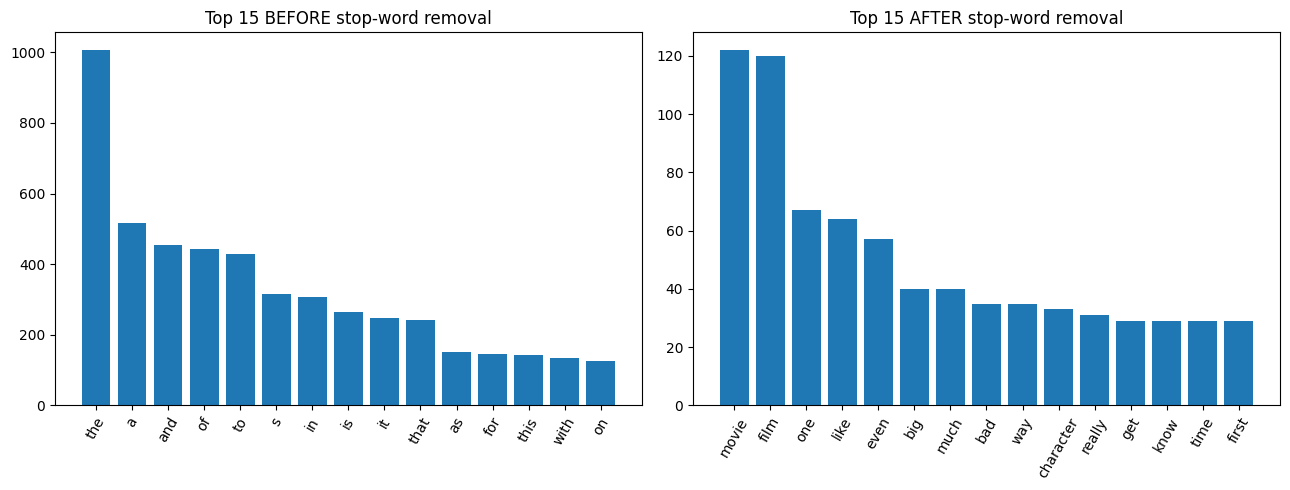

Top 15 BEFORE: ['the', 'a', 'and', 'of', 'to', 's', 'in', 'is', 'it', 'that', 'as', 'for', 'this', 'with', 'on']
Top 15 AFTER : ['movie', 'film', 'one', 'like', 'even', 'big', 'much', 'bad', 'way', 'character', 'really', 'get', 'know', 'time', 'first']


In [18]:
# Step 3: top-15 words before and after
from collections import Counter
import matplotlib.pyplot as plt

count_before = Counter([w for s in sentences for w in s])
count_after = Counter([w for s in sentences_no_stop for w in s])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, counter, title in [(axes[0], count_before, 'Top 15 BEFORE stop-word removal'),
                           (axes[1], count_after, 'Top 15 AFTER stop-word removal')]:
    top = counter.most_common(15)
    ax.bar([w for w, c in top], [c for w, c in top])
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()
print('Top 15 BEFORE:', [w for w, n in count_before.most_common(15)])
print('Top 15 AFTER :', [w for w, n in count_after.most_common(15)])

**Observation:** before removal the top words are all stop-words (the, a, and, of, to). After removal, the real content words (film, movie, one, like) appear. The vocabulary shrinks only slightly, but the token count drops a lot.

In [19]:
# Step 4: custom stop-word list
custom_stop = set(stop_words)

# REMOVE 6 words from the list (we want to KEEP them)
keep_words = ['not', 'no', 'nor', 'very', 'too', 'against']
for w in keep_words:
    custom_stop.discard(w)

# ADD 6 domain words (movie-review domain, very common but not useful)
add_words = ['movie', 'film', 'one', 'also', 'would', 'even']
for w in add_words:
    custom_stop.add(w)

print('Original size:', len(stop_words), ' Custom size:', len(custom_stop))
print('(6 removed + 6 added, so the size stays the same, but the CONTENT changed)')

# apply the custom list and compare
sentences_custom = []
for s in sentences:
    new_s = [w for w in s if w not in custom_stop]
    if len(new_s) > 0:
        sentences_custom.append(new_s)
c = stats(sentences_custom)
print('Token count     : NLTK list', a[0], '| custom list', c[0])
print('Vocabulary size : NLTK list', a[1], '| custom list', c[1])
print('Avg sentence len: NLTK list', round(a[2], 2), '| custom list', round(c[2], 2))
print('Top 15 after custom removal:', [w for w, n in Counter([w for s in sentences_custom for w in s]).most_common(15)])

Original size: 198  Custom size: 198
(6 removed + 6 added, so the size stays the same, but the CONTENT changed)
Token count     : NLTK list 9533 | custom list 9285
Vocabulary size : NLTK list 4017 | custom list 4017
Avg sentence len: NLTK list 10.55 | custom list 10.27
Top 15 after custom removal: ['not', 'like', 'no', 'big', 'much', 'bad', 'way', 'too', 'character', 'really', 'get', 'know', 'time', 'first', 'scene']


### Justification of the 12 changes
**Removed from the list (kept in text):**
| Word | Why keep it |
|---|---|
| not | flips sentiment ("not good") |
| no | negation ("no problem") |
| nor | negation ("nor good nor bad") |
| very | intensity ("very bad" vs "bad") |
| too | intensity/opinion ("too long") |
| against | shows direction/opinion ("against the plot") |

**Added to the list (removed from text):**
| Word | Why remove it |
|---|---|
| movie | appears in almost every movie review, tells nothing |
| film | same reason as movie |
| one | very common filler ("one of the best"), low value |
| also | linking word, no sentiment |
| would | helper verb, no sentiment |
| even | filler word, appears everywhere |

---
# Task 4: Risks of Stop-Word Removal (Sentiment, MT, Chatbots)
**Analogy:** Removing "not" from "do not touch the wire" gives "touch the wire". A tiny word completely reverses the instruction. That is the danger of blind stop-word removal.

In [20]:
# Part 1: Sentiment with negation
sentences = [
    "The food is not good",
    "I am never happy here",
    "This is no problem",
    "The movie was not bad",
    "I do not like this phone",
]

# tiny hand-made sentiment dictionary
positive = ['good', 'happy', 'like', 'great']
negative = ['bad', 'problem', 'worst']
negators = ['not', 'no', 'never']

def sentiment(words):
    score = 0
    for i in range(len(words)):
        value = 0
        if words[i] in positive:
            value = 1
        if words[i] in negative:
            value = -1
        # if the previous word is a negator, flip the value
        if i > 0 and words[i - 1] in negators:
            value = -value
        score = score + value
    if score > 0:
        return 'POSITIVE'
    if score < 0:
        return 'NEGATIVE'
    return 'NEUTRAL'

for s in sentences:
    original = s.lower().split()
    reduced = [w for w in original if w not in stop_words]   # NLTK removes not/no/never
    print(s)
    print('   original :', original, '->', sentiment(original))
    print('   reduced  :', reduced, '->', sentiment(reduced))

The food is not good
   original : ['the', 'food', 'is', 'not', 'good'] -> NEGATIVE
   reduced  : ['food', 'good'] -> POSITIVE
I am never happy here
   original : ['i', 'am', 'never', 'happy', 'here'] -> NEGATIVE
   reduced  : ['never', 'happy'] -> NEGATIVE
This is no problem
   original : ['this', 'is', 'no', 'problem'] -> POSITIVE
   reduced  : ['problem'] -> NEGATIVE
The movie was not bad
   original : ['the', 'movie', 'was', 'not', 'bad'] -> POSITIVE
   reduced  : ['movie', 'bad'] -> NEGATIVE
I do not like this phone
   original : ['i', 'do', 'not', 'like', 'this', 'phone'] -> NEGATIVE
   reduced  : ['like', 'phone'] -> POSITIVE


**Result:** 4 out of 5 sentences **flip** after stop-word removal: "not good" -> `good` (negative became positive), "no problem" -> `problem` (positive became negative), "not bad" -> `bad` (positive became negative), "do not like" -> `like` (negative became positive). The cause is that "not" and "no" are in NLTK's stop-word list. The 2nd sentence ("never happy") did not flip because "never" is not in NLTK's list.

In [21]:
# Part 2: Machine Translation
mt_original = [
    "I do not want to go to the market",
    "She is not at home today",
    "You should not eat that food",
]
mt_reduced = [[w for w in s.lower().split() if w not in stop_words] for s in mt_original]
for o, r in zip(mt_original, mt_reduced):
    print('ORIGINAL:', o)
    print('REDUCED :', ' '.join(r))
    print()

ORIGINAL: I do not want to go to the market
REDUCED : want go market

ORIGINAL: She is not at home today
REDUCED : home today

ORIGINAL: You should not eat that food
REDUCED : eat food



**Translation to Urdu.** I cannot open Google Translate from my work environment, so the Urdu below is *my own translation*. Please paste the English lines into Google Translate yourself and compare, then write your own screenshot or result in the report.

| English | Urdu |
|---|---|
| I do not want to go to the market | میں بازار نہیں جانا چاہتا |
| (reduced) want go market | چاہتا بازار جانا |
| She is not at home today | وہ آج گھر پر نہیں ہے |
| (reduced) home today | گھر آج |
| You should not eat that food | آپ کو وہ کھانا نہیں کھانا چاہیے |
| (reduced) eat food | کھانا کھاؤ |

**Observation:** the original sentences translate fully and correctly. The reduced ones become broken fragments, and the third one actually becomes a **command to eat** ("eat food") instead of a warning not to eat it. The meaning is badly distorted.

In [22]:
# Part 3: Chatbot intents
queries = [
    "How to not be charged?",
    "What is the status of my order?",
    "I do not want to cancel my subscription",
    "Where is my refund?",
    "How can I stop the payment?",
]
for q in queries:
    reduced = [w for w in q.lower().replace('?', '').split() if w not in stop_words]
    print(q, ' --> ', reduced)

How to not be charged?  -->  ['charged']
What is the status of my order?  -->  ['status', 'order']
I do not want to cancel my subscription  -->  ['want', 'cancel', 'subscription']
Where is my refund?  -->  ['refund']
How can I stop the payment?  -->  ['stop', 'payment']


**How the intent is damaged:**
- "How to not be charged?" becomes `charged` : the bot thinks the user is asking about a *charge*, not how to *avoid* one.
- "What is the status of my order?" becomes `status order` : this one still survives fine.
- "I do not want to cancel my subscription" becomes `want cancel subscription` : the bot now thinks the user WANTS to cancel (the opposite).
- "Where is my refund?" becomes `refund` : "where" is lost, so the bot cannot tell if the user is asking for the location/status or asking to *get* a refund.
- "How can I stop the payment?" becomes `stop payment` : OK here, but "how" is lost, so it is a command, not a question.

In [23]:
# Part 4: Safe strategy - keep negation (and question) words
safe_stop = set(stop_words)
for w in ['not', 'no', 'nor', 'never', 'how', 'what', 'where', 'why', 'when', "don't", "didn't",
          "doesn't", "isn't", "wasn't", "shouldn't", "won't", "can't"]:
    safe_stop.discard(w)

print('--- Sentiment re-test with safe list ---')
for s in sentences:
    original = s.lower().split()
    safe = [w for w in original if w not in safe_stop]
    print(s, '|', safe, '->', sentiment(safe), '(original was', sentiment(original) + ')')

print()
print('--- Chatbot re-test with safe list ---')
for q in queries:
    safe = [w for w in q.lower().replace('?', '').split() if w not in safe_stop]
    print(q, ' --> ', safe)

print()
print('--- Translation re-test ---')
for o in mt_original:
    print(o, ' --> ', ' '.join([w for w in o.lower().split() if w not in safe_stop]))

--- Sentiment re-test with safe list ---
The food is not good | ['food', 'not', 'good'] -> NEGATIVE (original was NEGATIVE)
I am never happy here | ['never', 'happy'] -> NEGATIVE (original was NEGATIVE)
This is no problem | ['no', 'problem'] -> POSITIVE (original was POSITIVE)
The movie was not bad | ['movie', 'not', 'bad'] -> POSITIVE (original was POSITIVE)
I do not like this phone | ['not', 'like', 'phone'] -> NEGATIVE (original was NEGATIVE)

--- Chatbot re-test with safe list ---
How to not be charged?  -->  ['how', 'not', 'charged']
What is the status of my order?  -->  ['what', 'status', 'order']
I do not want to cancel my subscription  -->  ['not', 'want', 'cancel', 'subscription']
Where is my refund?  -->  ['where', 'refund']
How can I stop the payment?  -->  ['how', 'stop', 'payment']

--- Translation re-test ---
I do not want to go to the market  -->  not want go market
She is not at home today  -->  not home today
You should not eat that food  -->  not eat food


**Result:** with the safe list, all 5 sentiment labels match the original, and the chatbot queries keep "not", "how", "what", "where". The strategy is: **never remove negation words or question words**.

---
# Task 5: Hands-On with the Porter Stemmer
**Analogy:** A stemmer is like cutting the branches of a tree with an axe. It is fast, but sometimes it cuts a real word in half ("studies" becomes "studi").

In [24]:
from nltk.stem import PorterStemmer, SnowballStemmer
porter = PorterStemmer()
snowball = SnowballStemmer('english')

words = ['running', 'runs', 'ran', 'studies', 'studying', 'studied', 'happily', 'happy',
         'happiness', 'generalization', 'generalize', 'general', 'better', 'good', 'was',
         'is', 'caring', 'cared', 'university', 'universe', 'universal', 'organization',
         'organize', 'organic', 'argue', 'argument', 'arguing', 'flies', 'fly', 'feet',
         'foot', 'meeting', 'meetings', 'easily', 'easy', 'relative', 'relate']
print('Number of words:', len(words))

Number of words: 37


In [25]:
# Steps 1-2: table  Word | Stem | Correct/Incorrect
# (Correct/Incorrect is MY manual judgement:
#  Correct   = stem is a real word/root and matches its word family
#  Incorrect = stem is not a real word (studi, happi), or mixes unrelated words,
#              or an irregular form (ran, better, feet) was not reduced to its base)
judgement = {
    'running': 'Correct', 'runs': 'Correct', 'ran': 'Incorrect',
    'studies': 'Incorrect', 'studying': 'Incorrect', 'studied': 'Incorrect',
    'happily': 'Incorrect', 'happy': 'Incorrect', 'happiness': 'Incorrect',
    'generalization': 'Incorrect', 'generalize': 'Incorrect', 'general': 'Incorrect',
    'better': 'Incorrect', 'good': 'Correct', 'was': 'Incorrect', 'is': 'Correct',
    'caring': 'Correct', 'cared': 'Correct',
    'university': 'Incorrect', 'universe': 'Incorrect', 'universal': 'Incorrect',
    'organization': 'Incorrect', 'organize': 'Incorrect', 'organic': 'Incorrect',
    'argue': 'Incorrect', 'argument': 'Incorrect', 'arguing': 'Incorrect',
    'flies': 'Incorrect', 'fly': 'Incorrect', 'feet': 'Incorrect', 'foot': 'Correct',
    'meeting': 'Correct', 'meetings': 'Correct', 'easily': 'Incorrect', 'easy': 'Incorrect',
    'relative': 'Incorrect', 'relate': 'Incorrect',
}
import pandas as pd
rows = []
for w in words:
    rows.append([w, porter.stem(w), judgement[w]])
pd.DataFrame(rows, columns=['Word', 'Stem', 'Correct/Incorrect'])

,Word,Stem,Correct/Incorrect
0,running,run,Correct
1,runs,run,Correct
2,ran,ran,Incorrect
3,studies,studi,Incorrect
4,studying,studi,Incorrect
5,studied,studi,Incorrect
6,happily,happili,Incorrect
7,happy,happi,Incorrect
8,happiness,happi,Incorrect
9,generalization,gener,Incorrect


Note on my labels: this is a judgement call, explained in the code comment above. Your teacher may be stricter or more relaxed (for example, `studi` groups studies/studying/studied correctly, but it is not a real word), so change any label you disagree with.

In [26]:
# Step 3: over-stemming and under-stemming examples
print('OVER-STEMMING (different meaning, same stem):')
for group in [['university', 'universe', 'universal'],
              ['organization', 'organize', 'organic'],
              ['policy', 'police']]:
    print('  ', [(w, porter.stem(w)) for w in group])

print()
print('UNDER-STEMMING (related words, different stems):')
for group in [['argue', 'argument'],
              ['ran', 'run', 'running'],
              ['feet', 'foot'],
              ['better', 'good'],
              ['was', 'is']]:
    print('  ', [(w, porter.stem(w)) for w in group])

OVER-STEMMING (different meaning, same stem):
   [('university', 'univers'), ('universe', 'univers'), ('universal', 'univers')]
   [('organization', 'organ'), ('organize', 'organ'), ('organic', 'organ')]
   [('policy', 'polici'), ('police', 'polic')]

UNDER-STEMMING (related words, different stems):
   [('argue', 'argu'), ('argument', 'argument')]
   [('ran', 'ran'), ('run', 'run'), ('running', 'run')]
   [('feet', 'feet'), ('foot', 'foot')]
   [('better', 'better'), ('good', 'good')]
   [('was', 'wa'), ('is', 'is')]


**Over-stemming:** university / universe / universal -> `univers`; organization / organize / organic -> `organ`; policy / police -> `polici`.
**Under-stemming:** argue -> `argu` but argument -> `argument`; ran vs run; feet vs foot; better vs good; was vs is.

In [27]:
# Step 4: Porter vs Snowball - where do they differ?
print('Word | Porter | Snowball')
for w in words:
    p = porter.stem(w)
    s = snowball.stem(w)
    if p != s:
        print(w, '|', p, '|', s)

Word | Porter | Snowball
generalization | gener | general
generalize | gener | general
general | gener | general
was | wa | was
relative | rel | relat


Snowball (Porter2) is a bit smarter: for example `general` stays `general` instead of `gener`, and `was` stays `was` instead of `wa`. For most other words both give the same stem.

---
# Task 6: Lemmatization (spaCy) vs. Stemming
**Analogy:** Stemming is cutting a word with an axe. Lemmatization is looking the word up in a dictionary to find its proper base form. The dictionary is slower but gives real words.

In [28]:
import spacy
nlp = spacy.load('en_core_web_sm')

paragraph = ("The children were running quickly through the gardens while their mothers were "
             "studying the better plans for the new houses. She had written several letters "
             "and was hoping that the teachers would be happier with the results. The cities "
             "are growing faster, and people have been moving to bigger homes. Yesterday, the "
             "players won their games and the fans were singing loudly in the streets. "
             "The students had finished their exams, and the professors were reading the "
             "papers carefully. Many families are buying cheaper cars, while the companies "
             "have been building better roads. He said the mice were hiding under the "
             "wooden boxes, and the women were laughing at the funny stories.")
print('Words in paragraph:', len(paragraph.split()))

doc = nlp(paragraph)
print('Tokens:', len(doc))

Words in paragraph: 112
Tokens: 124


In [29]:
# Steps 1-2: Token | POS | Stem | Lemma
rows = []
for token in doc:
    if token.is_alpha:
        rows.append([token.text, token.pos_, porter.stem(token.text), token.lemma_])
pd.set_option('display.max_rows', None)
comparison = pd.DataFrame(rows, columns=['Token', 'POS', 'Stem', 'Lemma'])
comparison

,Token,POS,Stem,Lemma
0,The,DET,the,the
1,children,NOUN,children,child
2,were,AUX,were,be
3,running,VERB,run,run
4,quickly,ADV,quickli,quickly
5,through,ADP,through,through
6,the,DET,the,the
7,gardens,NOUN,garden,garden
8,while,SCONJ,while,while
9,their,PRON,their,their


In [30]:
# Step 3: where does lemmatization do better?
better = comparison[(comparison['Stem'] != comparison['Lemma'].str.lower())]
better = better[better['Token'].str.lower() != better['Lemma'].str.lower()]
better

,Token,POS,Stem,Lemma
1,children,NOUN,children,child
2,were,AUX,were,be
11,were,AUX,were,be
12,studying,VERB,studi,study
14,better,ADJ,better,well
19,houses,NOUN,hous,house
21,had,AUX,had,have
22,written,VERB,written,write
26,was,AUX,wa,be
27,hoping,VERB,hope,hop


**Where lemmatization wins (from the table above):**
| Token | Stem | Lemma |
|---|---|---|
| were / was / been / are | were / wa / been / are | be |
| children / mice / women | children / mice / women | child / mouse / woman |
| written / won / said | written / won / said | write / win / say |
| happier / bigger / cheaper | happier / bigger / cheaper | happy / big / cheap |
| studying / cities / families | studi / citi / famili | study / city / family |

The stemmer cannot handle irregular words (were, mice, written, won) and produces non-words (`studi`, `citi`). It also over-stems: `carefully` -> `care`, which changes the meaning.

**Honest notes from the real output:**
- The lab example "better -> good" did **not** appear. spaCy's small model gave `better` -> `well`. The idea is the same (lemmatization finds a dictionary form, stemming leaves `better`), but the exact lemma depends on the model.
- Lemmatization is not perfect: `hoping` -> `hop` is a spaCy mistake (the stemmer's `hope` is better here).

**Role of the POS tag:** the lemmatizer needs to know the word type before it can pick the right base form. `were` is tagged AUX, so it maps to `be`; `better` is tagged ADJ, which is why it maps to an adjective/adverb base form. The same spelling can have different lemmas under different POS tags (for example "saw" as a verb -> `see`, as a noun -> `saw`). A stemmer ignores POS completely.

In [31]:
# Step 4: speed test
import time

tokens_text = [t.text for t in doc]
N = 200   # repeat many times to get a stable number

start = time.time()
for i in range(N):
    for w in tokens_text:
        porter.stem(w)
stem_time = time.time() - start

start = time.time()
for i in range(N):
    nlp(paragraph)
lemma_time = time.time() - start

print('Stemming  :', round(stem_time, 4), 'seconds for', N, 'runs')
print('Lemmatize :', round(lemma_time, 4), 'seconds for', N, 'runs')
print('Lemmatization is about', round(lemma_time / stem_time, 1), 'times slower')   # in my run it was about 15x slower

Stemming  : 0.5328 seconds for 200 runs
Lemmatize : 6.2058 seconds for 200 runs
Lemmatization is about 11.6 times slower


(The exact numbers change on every computer; run it on yours and write your own numbers in the report.)

**When to choose which:**
- **Stemming:** huge datasets, search engines, quick experiments where speed matters and exact words do not.
- **Lemmatization:** chatbots, translation, text that humans will read, any task where you need real dictionary words or must tell word types apart (it also gives POS tags as a bonus).

---
# Task 7: Preprocessing Pipeline
**Analogy:** A car wash with switchable stations: wash, soap, rinse, wax. You choose which stations to turn on, and compare how clean each car comes out.

In [32]:
import re
from nltk.corpus import movie_reviews

# 600 documents: 300 negative + 300 positive
neg_ids = movie_reviews.fileids('neg')[:300]
pos_ids = movie_reviews.fileids('pos')[:300]
docs = []
labels = []
for f in neg_ids:
    docs.append(movie_reviews.raw(f))
    labels.append('neg')
for f in pos_ids:
    docs.append(movie_reviews.raw(f))
    labels.append('pos')
print('Documents:', len(docs))

Documents: 600


In [33]:
# Step 1: configurable pipeline function
nlp_fast = spacy.load('en_core_web_sm', disable=['parser', 'ner'])   # faster
# keep negation words (safe strategy from Task 4)
pipe_stop = set(stop_words) - {'not', 'no', 'nor', 'never'}

def preprocess(text, lower=True, noise=True, stop=False, stem=False, lemma=False):
    if lower:
        text = text.lower()
    if noise:
        text = re.sub(r'<.*?>', ' ', text)            # html
        text = re.sub(r'http\S+', ' ', text)         # urls
        text = re.sub(r'[^a-zA-Z\s]', ' ', text)     # punctuation and numbers
        text = re.sub(r'\s+', ' ', text).strip()
    if lemma:
        tokens = [t.lemma_ for t in nlp_fast(text)]
        tokens = [t.lower() for t in tokens]
    else:
        tokens = text.split()                         # tokenization
    if stop:
        tokens = [w for w in tokens if w not in pipe_stop]
    if stem:
        tokens = [porter.stem(w) for w in tokens]
    return tokens

print(preprocess("The movies were NOT good <br> http://x.com!!", stop=True, lemma=True))

['movie', 'not', 'good']


In [34]:
# Step 2: 4 configurations
configs = {
    '1. lowercase only':          dict(),
    '2. lowercase + stop-words':  dict(stop=True),
    '3. lowercase + stemming':    dict(stem=True),
    '4. lowercase + lemmatization': dict(lemma=True),
}
processed = {}
for name, options in configs.items():
    processed[name] = [preprocess(d, **options) for d in docs]
    print('done', name)

done 1. lowercase only
done 2. lowercase + stop-words
done 3. lowercase + stemming
done 4. lowercase + lemmatization


In [35]:
# Step 3: table of vocabulary size and average tokens
rows = []
for name in configs:
    all_tokens = [t for d in processed[name] for t in d]
    vocab = len(set(all_tokens))
    avg = len(all_tokens) / len(docs)
    rows.append([name, vocab, round(avg, 1)])
pd.DataFrame(rows, columns=['Configuration', 'Vocabulary size', 'Avg tokens / doc'])

,Configuration,Vocabulary size,Avg tokens / doc
0,1. lowercase only,23373,638.9
1,2. lowercase + stop-words,23226,342.0
2,3. lowercase + stemming,15880,638.9
3,4. lowercase + lemmatization,18696,639.0


In [36]:
# Step 4: classification with TF-IDF + Logistic Regression (5-fold cross validation)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

results = []
for name in configs:
    texts = [' '.join(d) for d in processed[name]]
    model = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
    scores = cross_val_score(model, texts, labels, cv=5)     # 5 different train/test splits
    results.append([name, round(scores.mean(), 4), round(scores.std(), 4)])
pd.DataFrame(results, columns=['Configuration', 'Mean accuracy', 'Std (spread)'])

,Configuration,Mean accuracy,Std (spread)
0,1. lowercase only,0.7783,0.0360
1,2. lowercase + stop-words,0.7817,0.0318
2,3. lowercase + stemming,0.7883,0.0287
3,4. lowercase + lemmatization,0.7750,0.0394


**Analysis (5-fold cross-validation on 600 movie reviews, from the printed numbers):**
1. All four configurations score about 77.5% to 79%: lowercase only 0.778, + stop-words 0.782, + stemming 0.788, + lemmatization 0.775.
2. Stemming is highest, but it beats the lowest by only about 1.3 points, and the spread across folds (std about 0.03) is bigger than that gap, so I cannot claim a clear winner.
3. Stop-word removal cut the tokens per document almost in half (639 -> 342) with almost no change in accuracy, so it gives a much smaller input for free. (I kept "not/no/nor/never" so negation is not lost.)
4. Stemming shrank the vocabulary the most (23,373 -> 15,880) and lemmatization less (18,696), because lemmas stay real words.
5. Lemmatization was slowest and not more accurate here, so for this TF-IDF sentiment task stemming or stop-word removal is the practical choice.
6. A larger dataset or more folds would be needed to separate configurations that are this close.

---
# Task 8: Minimum Edit Distance (Levenshtein)
**Analogy:** Fixing a typo with the fewest key presses. To turn "kitten" into "sitting" you can insert, delete or replace letters. Edit distance is the smallest number of key presses needed.

In [37]:
# Step 1: recursive version (no memoization)
def lev_recursive(a, b):
    if len(a) == 0:
        return len(b)            # insert all of b
    if len(b) == 0:
        return len(a)            # delete all of a
    if a[-1] == b[-1]:
        cost = 0
    else:
        cost = 1
    return min(lev_recursive(a[:-1], b) + 1,           # delete
               lev_recursive(a, b[:-1]) + 1,           # insert
               lev_recursive(a[:-1], b[:-1]) + cost)   # substitute / match

print(lev_recursive('kitten', 'sitting'))
print(lev_recursive('sunday', 'saturday'))

3
3


**Limitation:** the same small sub-problems are solved again and again. The number of calls grows exponentially (about 3^n), so strings of length 15 to 20 already take very long. The next version fixes this by saving the answers in a table.

In [38]:
# Step 2: iterative dynamic programming (insert=1, delete=1, substitute=1)
def lev_dp(a, b, sub_cost=1):
    rows = len(a) + 1
    cols = len(b) + 1
    D = [[0] * cols for i in range(rows)]
    for i in range(rows):
        D[i][0] = i
    for j in range(cols):
        D[0][j] = j
    for i in range(1, rows):
        for j in range(1, cols):
            if a[i - 1] == b[j - 1]:
                cost = 0
            else:
                cost = sub_cost
            D[i][j] = min(D[i - 1][j] + 1,          # deletion
                          D[i][j - 1] + 1,          # insertion
                          D[i - 1][j - 1] + cost)   # substitution
    return D

# Step 3: print the table
def print_table(a, b, D):
    print('    ' + ''.join([f'{c:>3}' for c in ['#'] + list(b)]))
    for i in range(len(a) + 1):
        letter = '#' if i == 0 else a[i - 1]
        print(f'{letter:>3} ' + ''.join([f'{v:>3}' for v in D[i]]))

pairs = [('intention', 'execution'), ('kitten', 'sitting'), ('sunday', 'saturday')]
for a, b in pairs:
    D = lev_dp(a, b)
    print('\n', a, '->', b, ' distance =', D[-1][-1])
    print_table(a, b, D)


 intention -> execution  distance = 5
      #  e  x  e  c  u  t  i  o  n
  #   0  1  2  3  4  5  6  7  8  9
  i   1  1  2  3  4  5  6  6  7  8
  n   2  2  2  3  4  5  6  7  7  7
  t   3  3  3  3  4  5  5  6  7  8
  e   4  3  4  3  4  5  6  6  7  8
  n   5  4  4  4  4  5  6  7  7  7
  t   6  5  5  5  5  5  5  6  7  8
  i   7  6  6  6  6  6  6  5  6  7
  o   8  7  7  7  7  7  7  6  5  6
  n   9  8  8  8  8  8  8  7  6  5

 kitten -> sitting  distance = 3
      #  s  i  t  t  i  n  g
  #   0  1  2  3  4  5  6  7
  k   1  1  2  3  4  5  6  7
  i   2  2  1  2  3  4  5  6
  t   3  3  2  1  2  3  4  5
  t   4  4  3  2  1  2  3  4
  e   5  5  4  3  2  2  3  4
  n   6  6  5  4  3  3  2  3

 sunday -> saturday  distance = 3
      #  s  a  t  u  r  d  a  y
  #   0  1  2  3  4  5  6  7  8
  s   1  0  1  2  3  4  5  6  7
  u   2  1  1  2  2  3  4  5  6
  n   3  2  2  2  3  3  4  5  6
  d   4  3  3  3  3  4  3  4  5
  a   5  4  3  4  4  4  4  3  4
  y   6  5  4  4  5  5  5  4  3


**By hand (Step 3):** the lab asks you to build these three tables by hand on paper. Use the printed tables above to *check* your hand-made tables. Rule for each cell: `min(cell above + 1, cell left + 1, cell diagonal + (0 if letters equal else 1))`.

In [39]:
# Step 4: backtrace - which operations were used?
def backtrace(a, b, sub_cost=1):
    D = lev_dp(a, b, sub_cost)
    i = len(a)
    j = len(b)
    ops = []
    while i > 0 or j > 0:
        if i > 0 and j > 0:
            if a[i - 1] == b[j - 1]:
                cost = 0
            else:
                cost = sub_cost
            if D[i][j] == D[i - 1][j - 1] + cost:
                if cost == 0:
                    ops.append('keep ' + a[i - 1])
                else:
                    ops.append('substitute ' + a[i - 1] + ' -> ' + b[j - 1])
                i = i - 1
                j = j - 1
                continue
        if i > 0 and D[i][j] == D[i - 1][j] + 1:
            ops.append('delete ' + a[i - 1])
            i = i - 1
            continue
        ops.append('insert ' + b[j - 1])
        j = j - 1
    ops.reverse()
    return D[-1][-1], ops

for a, b in pairs:
    for cost in [1, 2]:
        dist, ops = backtrace(a, b, cost)
        print(a, '->', b, '| substitution cost =', cost, '| distance =', dist)
        print('    ', ops)
    print()

intention -> execution | substitution cost = 1 | distance = 5
     ['substitute i -> e', 'substitute n -> x', 'substitute t -> e', 'substitute e -> c', 'substitute n -> u', 'keep t', 'keep i', 'keep o', 'keep n']
intention -> execution | substitution cost = 2 | distance = 8
     ['delete i', 'substitute n -> e', 'substitute t -> x', 'keep e', 'insert c', 'substitute n -> u', 'keep t', 'keep i', 'keep o', 'keep n']

kitten -> sitting | substitution cost = 1 | distance = 3
     ['substitute k -> s', 'keep i', 'keep t', 'keep t', 'substitute e -> i', 'keep n', 'insert g']
kitten -> sitting | substitution cost = 2 | distance = 5
     ['substitute k -> s', 'keep i', 'keep t', 'keep t', 'substitute e -> i', 'keep n', 'insert g']

sunday -> saturday | substitution cost = 1 | distance = 3
     ['keep s', 'insert a', 'insert t', 'keep u', 'substitute n -> r', 'keep d', 'keep a', 'keep y']
sunday -> saturday | substitution cost = 2 | distance = 4
     ['keep s', 'insert a', 'insert t', 'keep u',

**Comparison (from the printed output):** with substitution cost 2, a substitution costs as much as one delete + one insert, so all distances go up: intention/execution 5 -> 8, kitten/sitting 3 -> 5, sunday/saturday 3 -> 4. For kitten/sitting (2 substitutions + 1 insert) and sunday/saturday (1 substitution + 2 inserts) the path stays the same, only the cost rises. For intention/execution the path itself changes: it now uses `delete i` and `insert c` instead of five substitutions. The cost-2 version is the Jurafsky and Martin style.

---
# Task 9: Spelling Correction with Edit Distance
**Analogy:** Phone auto-correct. You type a wrong word, the phone looks at all the dictionary words, and suggests the closest ones. If two are equally close, it suggests the one people use more often.

In [40]:
# Step 1: dictionary of 5000+ words from the Brown corpus
from nltk.corpus import brown
from collections import Counter

freq = Counter([w.lower() for w in brown.words() if w.isalpha()])
dictionary = [w for w, c in freq.most_common(20000)]
print('Dictionary size:', len(dictionary))

Dictionary size: 20000


In [41]:
# Step 2: suggest() using edit distance (version 1: distance only)
def edit_distance(a, b):
    return lev_dp(a, b)[-1][-1]

def suggest(word, k=5):
    scored = []
    for d in dictionary:
        if abs(len(d) - len(word)) <= 2:        # small speed-up
            scored.append((edit_distance(word, d), d))
    scored.sort()      # sort by distance only; equal distances fall back to alphabetical order
    return [d for dist, d in scored[:k]]

print(suggest('recieve'))

['relieve', 'believe', 'recede', 'receive', 'recipe']


In [42]:
# Step 3: test on 15 misspelled words
tests = [
    ('recieve', 'receive'), ('definately', 'definitely'), ('acommodate', 'accommodate'),
    ('seperate', 'separate'), ('occured', 'occurred'), ('untill', 'until'),
    ('wich', 'which'), ('beleive', 'believe'), ('goverment', 'government'),
    ('enviroment', 'environment'), ('tommorow', 'tomorrow'), ('freind', 'friend'),
    ('begining', 'beginning'), ('publically', 'publicly'), ('neccessary', 'necessary'),
]
for wrong, right in tests:
    if right not in dictionary:
        print('WARNING: correct word not in dictionary:', right)

correct = 0
in_top5 = 0
for wrong, right in tests:
    top = suggest(wrong, 5)
    ok = (top[0] == right)
    if ok:
        correct = correct + 1
    if right in top:
        in_top5 = in_top5 + 1
    print(wrong, '->', top, '| expected:', right, '| top-1', 'YES' if ok else 'NO')
print('Top-1 accuracy (distance only):', correct, '/', len(tests), '=', round(correct / len(tests), 2))
print('Correct word anywhere in top-5 :', in_top5, '/', len(tests))

recieve -> ['relieve', 'believe', 'recede', 'receive', 'recipe'] | expected: receive | top-1 NO
definately -> ['definitely', 'definite', 'indefinitely', 'infinitely', 'adequately'] | expected: definitely | top-1 YES
acommodate -> ['accommodate', 'commodity', 'commodore', 'accumulate', 'commodities'] | expected: accommodate | top-1 YES
seperate -> ['separate', 'desperate', 'generate', 'operate', 'separated'] | expected: separate | top-1 YES
occured -> ['occurred', 'accused', 'cured', 'obscured', 'occluded'] | expected: occurred | top-1 YES
untill -> ['until', 'still', 'till', 'untold', 'antics'] | expected: until | top-1 YES
wich -> ['rich', 'which', 'wick', 'wish', 'witch'] | expected: which | top-1 NO
beleive -> ['believe', 'receive', 'alive', 'beatie', 'bedside'] | expected: believe | top-1 YES
goverment -> ['government', 'governments', 'movement', 'coherent', 'divergent'] | expected: government | top-1 YES
enviroment -> ['environment', 'environments', 'enrichment', 'environs', 'advi

In [43]:
# Step 4: break ties using word frequency
def suggest_freq(word, k=5):
    scored = []
    for d in dictionary:
        if abs(len(d) - len(word)) <= 2:
            scored.append((edit_distance(word, d), -freq[d], d))   # distance first, then higher frequency
    scored.sort()
    return [d for dist, f, d in scored[:k]]

correct2 = 0
in_top5_2 = 0
for wrong, right in tests:
    top = suggest_freq(wrong, 5)
    ok = (top[0] == right)
    if ok:
        correct2 = correct2 + 1
    if right in top:
        in_top5_2 = in_top5_2 + 1
    print(wrong, '->', top, '| top-1', 'YES' if ok else 'NO')
print()
print('Version 1 (distance only)      :', correct, '/', len(tests))
print('Version 2 (distance + frequency):', correct2, '/', len(tests))
print('Top-5 coverage, version 1:', in_top5, '/', len(tests), '| version 2:', in_top5_2, '/', len(tests))

recieve -> ['relieve', 'believe', 'receive', 'relieved', 'recipe'] | top-1 NO
definately -> ['definitely', 'definite', 'indefinitely', 'infinitely', 'definition'] | top-1 YES
acommodate -> ['accommodate', 'commodity', 'commodore', 'commodities', 'corporate'] | top-1 YES
seperate -> ['separate', 'operate', 'separated', 'desperate', 'generate'] | top-1 YES
occured -> ['occurred', 'occur', 'occupied', 'occurs', 'accused'] | top-1 YES
untill -> ['until', 'still', 'till', 'untold', 'will'] | top-1 YES
wich -> ['with', 'which', 'wish', 'rich', 'witch'] | top-1 NO
beleive -> ['believe', 'receive', 'leave', 'received', 'beside'] | top-1 YES
goverment -> ['government', 'movement', 'governments', 'movements', 'governing'] | top-1 YES
enviroment -> ['environment', 'environments', 'environs', 'enrichment', 'government'] | top-1 YES
tommorow -> ['tomorrow', 'common', 'somehow', 'commerce', 'comfort'] | top-1 YES
freind -> ['find', 'friend', 'trend', 'fred', 'remind'] | top-1 NO
begining -> ['beginn

**Observations (from the real output above):**
- Top-1 accuracy was the same for both versions (12/15 = 0.80). The tie-break did not fix the 3 misses: `recieve` (a swapped letter pair costs 2 edits, so `relieve`, which is only 1 substitution away, wins), `wich` (`with` and `which` are both 1 edit away, and the more frequent word `with` wins), and `freind` (`find` and `friend` are both 2 edits away, and the more frequent `find` wins).
- Frequency did help the ranking: `friend` moved into the top-5 list and `receive` moved up one place, so the top-5 coverage increased (see the printed line).
- Weakness 1: plain Levenshtein counts a swapped pair of letters (ie/ei) as 2 edits. Damerau-Levenshtein counts it as 1 and would fix `recieve` and `freind`.
- Weakness 2: frequency can also choose the wrong word (`with` instead of `which`), because it only knows how common a word is, not what the sentence means.
- It compares against every dictionary word, so it is slow for big dictionaries.

**Why "their / there" is not caught:** "their" and "there" are both real dictionary words, so a dictionary-based checker thinks nothing is wrong. Real-word errors need the *context* (the neighbouring words), so we need a language model or n-grams, not just edit distance.